# Task 1: 2020 data only

### 0. Data Exploration

In [1]:
import pandas as pd
import torch

In [4]:
housing_df = pd.read_csv("data/housing_2020_train.csv")
housing_df.columns

Index(['median_income', 'population', 'households', 'housing_age', 'latitude',
       'longitude', 'median_house_value', 'fold'],
      dtype='str')

In [41]:
housing_df.describe()

,median_income,population,households,housing_age,latitude,longitude,median_house_value,fold
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,5.000000e+02,500.00000
mean,94308.232000,1570.264000,518.002000,48.66400,35.806872,-119.693055,6.263332e+05,2.00000
std,48242.421072,738.553042,234.607381,16.82621,2.158656,2.042241,4.003878e+05,1.41563
min,14175.000000,302.000000,123.000000,7.00000,32.576775,-124.193059,9.999000e+03,0.00000
25%,58699.250000,1023.250000,350.750000,38.00000,33.943271,-121.860720,3.524750e+05,1.00000
50%,83463.000000,1479.500000,471.500000,49.50000,34.530846,-119.080475,5.278500e+05,2.00000
75%,119123.750000,1933.500000,652.250000,61.25000,37.771637,-118.031144,7.747000e+05,3.00000
max,250001.000000,5075.000000,1981.000000,81.00000,41.921269,-114.657445,2.000001e+06,4.00000


In [42]:
housing_df.shape, housing_df.isna().sum()

((500, 8),
 median_income         0
 population            0
 households            0
 housing_age           0
 latitude              0
 longitude             0
 median_house_value    0
 fold                  0
 dtype: int64)

In [43]:
housing_df.value_counts(subset=housing_df.fold)

fold
2    100
4    100
1    100
3    100
0    100
Name: count, dtype: int64

In [30]:
import matplotlib.pyplot as plt

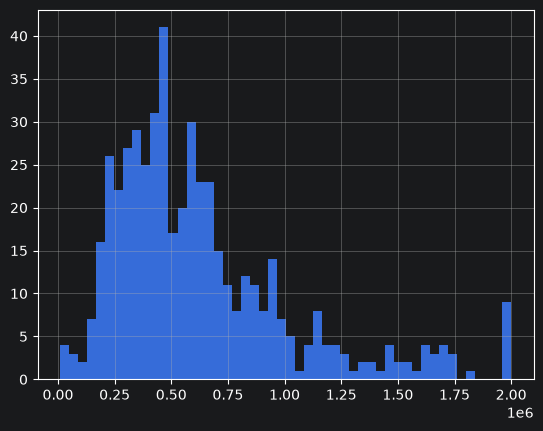

In [44]:
housing_df['median_house_value'].hist(bins=50)
plt.show()

In [45]:
housing_df.value_counts(subset=housing_df.median_house_value == 2000001), housing_df.value_counts(subset=housing_df.median_income == 250001), housing_df.value_counts(subset=housing_df.housing_age == 81)

(median_house_value
 False    491
 True       9
 Name: count, dtype: int64,
 median_income
 False    494
 True       6
 Name: count, dtype: int64,
 housing_age
 False    484
 True      16
 Name: count, dtype: int64)

### 1. Helper Functions

In [56]:
FEATURES = ['median_income', 'population', 'households', 'housing_age', 'latitude', 'longitude']
TARGET = 'median_house_value'
SEED = 42

In [61]:
import numpy as np

In [72]:
def split_data(dataset, fold_number=None):
    if fold_number is not None:
        is_train = dataset['fold'] != fold_number
        X_train, y_train, X_val, y_val = dataset[is_train][FEATURES], dataset[is_train][TARGET], dataset[~is_train][FEATURES], dataset[~is_train][TARGET]
        return X_train.to_numpy(dtype=np.float32), y_train.to_numpy(dtype=np.float32), X_val.to_numpy(dtype=np.float32), y_val.to_numpy(dtype=np.float32)
    else:
        X_train, y_train = dataset[FEATURES], dataset[TARGET]
        return X_train.to_numpy(dtype=np.float32), y_train.to_numpy(dtype=np.float32), None, None

In [74]:
class Standardizer:
    def __init__(self, X, y):
        self.mu_x = np.mean(X, axis=0)
        self.sigma_x = np.std(X, axis=0)
        self.mu_y = np.mean(y, axis=0)
        self.sigma_y = np.std(y, axis=0)

    def transform_X(self, X):
        return (X - self.mu_x) / self.sigma_x

    def transform_y(self, y):
        return (y - self.mu_y) / self.sigma_y

    def inverse(self, y_hat):
        return (y_hat * self.sigma_y) + self.mu_y

In [94]:
import torch
from torch import nn

In [95]:
def build_model(p=0.0, seed=SEED):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(6, 64),
        nn.ReLU(),
        nn.Dropout(p),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Dropout(p),
        nn.Linear(64, 1)
    )

In [106]:
def train(model, X_train, y_train, X_val, y_val, lr, epochs, loss_type='MSE'):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if loss_type == 'MSE':
        loss_fn = nn.MSELoss()
    elif loss_type == 'L1':
        loss_fn = nn.L1Loss()
    else:
        raise ValueError('Invalid loss type')

    train_mae = []
    val_mae = []

    # Standardize the training data
    standardizer = Standardizer(X_train, y_train)
    X_train_standardized = torch.from_numpy(standardizer.transform_X(X_train))
    y_train_standardized = torch.from_numpy(standardizer.transform_y(y_train))
    y_train_dollars = torch.from_numpy(y_train)

    if X_val is not None:
        X_val_standardized = torch.from_numpy(standardizer.transform_X(X_val))
        y_val_dollars = torch.from_numpy(y_val)

    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_hat = model(X_train_standardized).squeeze(1)
        loss = loss_fn(y_hat, y_train_standardized)
        loss.backward()
        optimizer.step()

        #Measure the error
        model.eval()
        with torch.no_grad():
            y_training_standardized_hat = model(X_train_standardized).squeeze(1)
            y_train_hat = standardizer.inverse(y_training_standardized_hat)
            train_mae.append(torch.mean(torch.abs(y_train_hat - y_train_dollars)).item())
            if X_val is not None:
                y_val_standardized_hat = model(X_val_standardized).squeeze(1)
                y_val_hat = standardizer.inverse(y_val_standardized_hat)
                val_mae.append(torch.mean(torch.abs(y_val_hat - y_val_dollars)).item())

    return train_mae, val_mae, standardizer


### 1.1 Testing Model

In [134]:
X_train, y_train, X_val, y_val = split_data(housing_df, 0)
model = build_model()

train_mae, val_mae, std = train(model, X_train, y_train, X_val, y_val, epochs=2000, lr=1e-3)

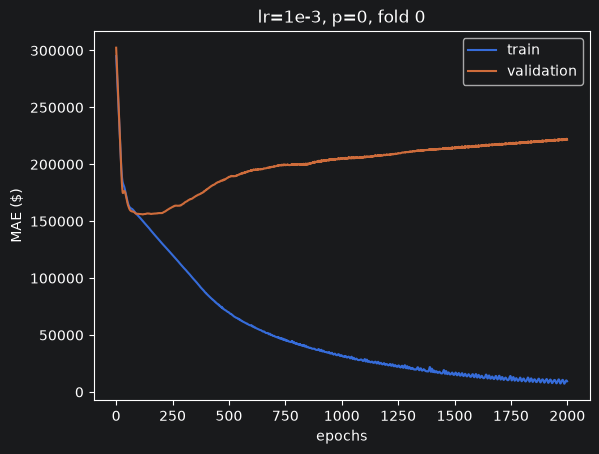

In [137]:
plt.plot(train_mae, label="train"), plt.plot(val_mae, label="validation"), plt.legend();
plt.xlabel("epochs")
plt.ylabel("MAE ($)")
plt.title("lr=1e-3, p=0, fold 0")

plt.savefig("figures/1-1.png", dpi=200, bbox_inches="tight")